In [1]:
import pandas as pd
import seaborn as sns

from math import floor
from copy import deepcopy

import random

In [2]:
sns.set(rc={'figure.figsize': (11.7, 8.27)})

In [3]:
# Установка библиотеки sklearn (пакет "sklearn" на PyPI устарел, ставится scikit-learn)
# !pip3 install scikit-learn

In [4]:
from sklearn.linear_model import LinearRegression

In [5]:
class ShuffleOnceRandom():
    """
    Генератор случайных чисел, который запрещает использовать
    функцию shuffle больше одного раза.
    """
    
    def __init__(self, seed=None):
        import random
        
        self._random_gen = random.Random(seed)
        self._shuffle_cnt = 0
        
    def shuffle(self, l):
        if self._shuffle_cnt > 0:
            raise RuntimeError('Нельзя использовать функцию shuffle больше одного раза')
            
        self._shuffle_cnt += 1
        self._random_gen.shuffle(l)

In [6]:
class ChoicesNRandom():
    """
    Генератор случайных чисел, который запрещает использовать
    функцию choices больше n раз.
    """
    
    def __init__(self, seed=None, n=1):
        import random
        
        self._random_gen = random.Random(seed)
        self._choices_cnt = 0
        self._n = n
        
    def choices(self, *args, **kwargs):
        if self._choices_cnt >= self._n:
            raise RuntimeError(f'Нельзя использовать функцию choices больше {self._n} раз')
            
        self._choices_cnt += 1
        return self._random_gen.choices(*args, **kwargs)

# Разбиение на обучающую, валидационную и тестовую выборки

In [7]:
def train_test_split_solution(data, 
                              train_frac,
                              random_gen):
    """
    Разбивает переданный список объектов на обучающую и тестовую выборки.
    
    Аргументы:
        data: Список объектов, который нужно разделить на части.
        train_frac: Доля объектов, которые нужно отправить в обучающую выборку.
        random_gen: Генератор случайных чисел.
        
    Возвращаемое значение:
        Пара списков: обучающая выборка, тестовая выборка.
    """
    
    data_copy = deepcopy(data)
    random_gen.shuffle(data_copy)
    n_train = floor(len(data_copy) * train_frac)
    return data_copy[:n_train], data_copy[n_train:]

In [8]:
def train_test_split_tests():
    example_1_data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
    example_1_train_frac = 0.7
    example_1_random_gen = ShuffleOnceRandom(0)
    
    example_1_res = [8, 9, 2, 6, 4, 5, 3], [1, 10, 7]
    
    assert train_test_split_solution(example_1_data, 
                                     example_1_train_frac, 
                                     example_1_random_gen) == example_1_res
    
    
    example_2_data = [i % 5 for i in range(100)]
    example_2_train_frac = 0.9
    example_2_random_gen = ShuffleOnceRandom(0)
    
    example_2_res = [3, 3, 1, 2, 3, 3, 1, 1, 4, 4, 1, 3, 2, 1, 0, 2, 2, 2, 3, 1, 4, 1, 4, 0, 4, 0, 2, 4, 3, 2, 3, 1, 3, 4, 1, 3, 4, 3, 4, 4, 4, 0, 4, 0, 0, 1, 1, 1, 2, 2, 3, 0, 4, 0, 3, 1, 1, 0, 2, 0, 3, 2, 3, 0, 1, 0, 1, 0, 0, 4, 0, 1, 0, 2, 4, 2, 4, 3, 2, 3, 2, 4, 2, 0, 1, 2, 4, 2, 4, 0], [1, 3, 1, 2, 0, 3, 0, 3, 2, 4]
    
    assert train_test_split_solution(example_2_data, 
                                     example_2_train_frac, 
                                     example_2_random_gen) == example_2_res
    
    print('Все тесты прошли успешно!')

In [9]:
train_test_split_tests()

Все тесты прошли успешно!


# Кросс-валидация

In [10]:
def round_to_3(x):
    """
    Принимает число и возвращает результат его округления
    до 3 знаков после запятой.
    
    Аргументы:
        x: Число.
        
    Возвращаемое значение:
        Результат округления числа до 3 знаков после запятой.
    """
    
    return round(x, 3)

In [11]:
def split_into_k(l, k):
    """
    Разделяет список на k частей.
    
    Аргументы:
        l: Список с объектами.
        k: Число частей, на которые нужно разделить список.
        
    Возвращаемое значение:
        Возвращает список из k частей исходного списка.
    """
    
    l_mod_k = len(l) % k
    l_div_k = len(l) // k
    
    res = []
    
    for i in range(k):
        res.append(l[i * l_div_k:(i + 1) * l_div_k])
        
    for i in range(l_mod_k):
        res[i].append(l[l_div_k * k + i])
        
    return res

def score_model(model, x_test, y_test):
    """
    Оценивает точность модели по метрике «среднее отклонение от предсказанного значения».
    
    Аргументы:
        model: Модель.
        x_test: Список объектов тестовой выборки.
        y_test: Список значений предсказываемой характеристики для объектов из тестовой выборки.
                Значение на $i$-ой позиции в списке соответствует $i$-ому объекту тестовой выборки.
        
    Возвращаемое значение:
        Точность модели.
    """
    
    y_pred = model.predict(x_test)
    
    res = 0

    for i in range(len(y_test)):
        res += abs(y_pred[i] - y_test[i])
        
    return res / len(y_test)

In [12]:
def k_fold_solution(model, data_x, data_y, k, random_gen):
    """
    Проводит кросс-валидацию заданной модели методом k-Fold.
    
    Аргументы:
        model: Модель, точность которой нужно оценить с помощью кросс-валидации.
        data_x: Список объектов, на основе которых нужно построить модель.
                Каждый объект представлен списком значений факторов.
        data_y: Список значений предсказываемой величины для каждого из объектов.
                На $i$-ой позиции в списке data_y находится предсказываемое
                значение для $i$-го объекта из списка data_x.
             k: Количество частей, на которые нужно разбить данные при кросс-валидации.
        random_gen: Генератор случайных чисел.
        
    Возвращаемое значение:
        Усреднённая по всем итерациям k-Fold точность модели.
    """
    
    data_xy = list(zip(data_x, data_y))
    random_gen.shuffle(data_xy)
    folds = split_into_k(data_xy, k)
    total = 0
    for i in range(k):
        train = [xy for j, fold in enumerate(folds) if j != i for xy in fold]
        model.fit([x for x, _ in train], [y for _, y in train])
        total += score_model(model, [x for x, _ in folds[i]], [y for _, y in folds[i]])
    return round_to_3(total / k)

In [13]:
def k_fold_test():
    data_x_example_1 = [[1], [2], [3]]
    data_y_example_1 = [1, 2, 3]
    
    assert k_fold_solution(LinearRegression(), 
                           data_x_example_1, data_y_example_1, 3, 
                           ShuffleOnceRandom(0)) == 0.0
    
    data_example_2 = pd.read_csv('k_fold_test_data.csv')
    
    data_x_example_2 = [[x] for x in list(data_example_2['x'])]
    data_y_example_2 = list(data_example_2['y'])
    
    assert k_fold_solution(LinearRegression(), 
                           data_x_example_2, data_y_example_2, 100, 
                           ShuffleOnceRandom(0)) == 0.602
    
    print('Тест прошёл успешно!')

In [14]:
k_fold_test()

Тест прошёл успешно!


# Погрешность оценки качества

In [15]:
error_modeling_data = pd.read_csv('error_modelling.csv')

In [16]:
y = list(error_modeling_data['y'])
y_pred = list(error_modeling_data['y_pred'])

In [17]:
y_and_y_pred = list(zip(y, y_pred))

In [18]:
error_modeling_random_gen = random.Random(0)

errs = []

for i in range(10_000):
    
    sample = error_modeling_random_gen.sample(y_and_y_pred, 100)
    errs.append(sum(abs(yi - yi_pred) for yi, yi_pred in sample) / len(sample))

<Axes: ylabel='Count'>

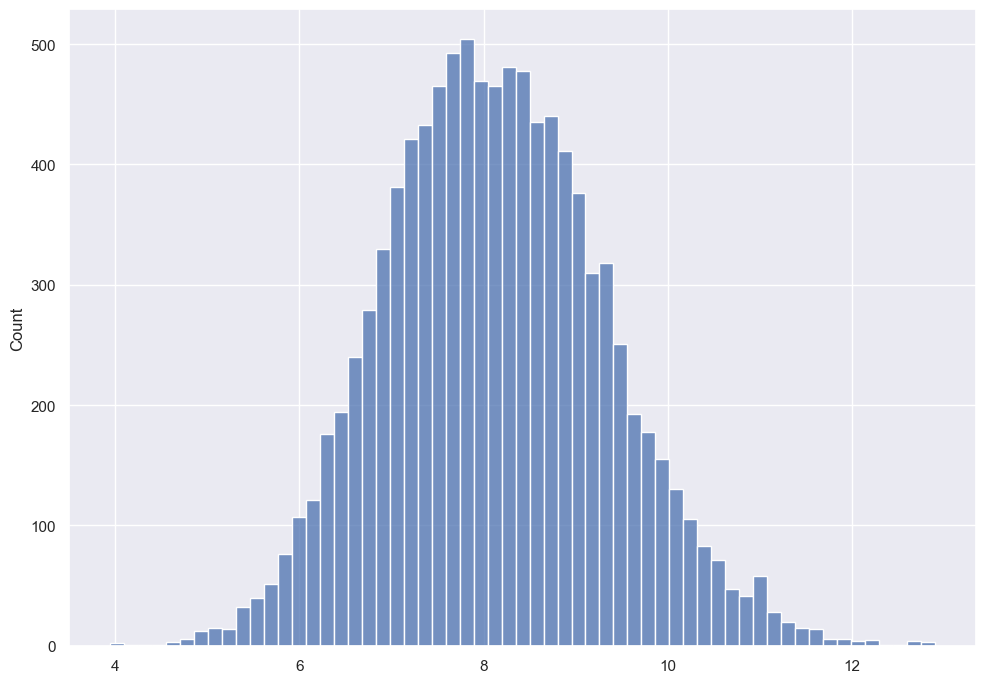

In [19]:
sns.histplot(errs)

Распределение похоже на нормальное с центром около 8 — соответствует графику **C**.

In [20]:
errs_mean = sum(errs) / len(errs)
errs_spread = (sum((e - errs_mean) ** 2 for e in errs) / len(errs)) ** (1/2)
print('Разброс оценок точности:', round(errs_spread, 3))

Разброс оценок точности: 1.205


In [21]:
full_err = sum(abs(yi - yi_pred) for yi, yi_pred in y_and_y_pred) / len(y_and_y_pred)
mean_err = sum(errs) / len(errs)
print('Точность по всем данным:', round(full_err, 3))
print('Среднее оценок по выборкам:', round(mean_err, 3))
print('Ответ (модуль разности):', round(abs(full_err - mean_err), 3))

Точность по всем данным: 8.127
Среднее оценок по выборкам: 8.131
Ответ (модуль разности): 0.004


# Бутстрап

In [22]:
def cut_on_edges(l, fraction_to_cut):
    """
    Отбрасывает с левого и с правого концов переданного списка заданную долю элементов.
    
    Аргументы:
        l: Список элементов.
        fraction_to_cut: Доля элементов, которую нужно отбросить с каждой из сторон списка.
        
    Возвращаемое значение:
        Новый список, в котором с левого и с правого концов отборешна заданная доля элементов.
    """
    
    to_cut = floor(len(l) * fraction_to_cut)
    return l[to_cut:len(l) - to_cut]

In [23]:
def bootstrap_confidence_interval_solution(y, y_pred, fraction_to_cut, random_gen):
    """
    Вычисляет доверительный интервал для точности модели на тестовой выборке с помощью бутстрапа.
    
    Аргументы:
        y: Реальные значения предсказываемой характеристики для объектов тестовой выборки.
        y_pred: Предсказанные с помощью модели значения характеристики для объектов тестовой выборки.
                $i$-ый элемент списка y_pred соответствует предсказанию моделью
                значения под номером $i$ в списке y.
        fraction_to_cut: Доля элементов, которую нужно отбросить с каждого из концов списка полученных с помощью
                         бутстрапа значений перед получением доверительного интервала.
        random_gen: Генератор случайных чисел.
        
    Возвращаемое значение:
        Доверительный интервал для точности модели, оценённой по метрике
        «среднее отклонение от предсказанного значения».
        Представляется в виде пары значений: левая граница интервала, правая граница интервала.
    """
    
    y_y_pred = list(zip(y, y_pred))
    errs = []
    for _ in range(10000):
        sample = random_gen.choices(y_y_pred, k=len(y_y_pred))
        errs.append(sum(abs(yi - yi_pred) for yi, yi_pred in sample) / len(sample))
    errs = cut_on_edges(sorted(errs), fraction_to_cut)
    return round_to_3(errs[0]), round_to_3(errs[-1])

In [24]:
def bootstrap_confidence_interval_test():
    error_modeling_data = pd.read_csv('error_modelling.csv')
    
    y = list(error_modeling_data['y'])
    y_pred = list(error_modeling_data['y_pred'])
    
    y_y_pred = list(zip(y, y_pred))
    
    random_gen = random.Random(0)
    y_y_pred_example_1 = random_gen.sample(y_y_pred, 100)
    
    y_example_1 = [x[0] for x in y_y_pred_example_1]
    y_pred_example_1 = [x[1] for x in y_y_pred_example_1]
    random_gen_example_1 = ChoicesNRandom(0, n=10000)
    
    res_example_1 = 7.178, 13.509
    
    assert bootstrap_confidence_interval_solution(y_example_1, y_pred_example_1, 0.025, random_gen_example_1) == res_example_1
    
    print('Тест прошёл успешно!')

In [25]:
bootstrap_confidence_interval_test()

Тест прошёл успешно!
